# The Economics of Electric Vehicles: a data walkthrough

This notebook turns the key figures from my bachelor's thesis *"Viaggio nelle auto elettriche: una prospettiva economica su innovazione e investimenti"* (Roma Tre University, 2025) into small datasets and charts.

**Questions:**
1. Where does the production cost of an EV come from?
2. How volatile is lithium, the battery's key raw material?
3. How fast are European countries adopting EVs?
4. Is charging infrastructure keeping up?
5. How big could the charging market become by 2030?
6. How large is China's investment lead?

All the data are in `../data/` as CSV files. Each row has a `source` column.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

# Shared style: one accent colour, everything else in neutral grey
ACCENT = "#2a78d6"      # blue
HIGHLIGHT = "#eb6834"   # orange, used to point at one bar
NEUTRAL = "#c3c2b7"     # grey
INK = "#52514e"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": NEUTRAL,
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "font.size": 10,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

## 1. Where does the cost of an EV come from?

An EV has fewer parts than a petrol car (no exhaust, no oil filter, no pistons), but it is **not** cheaper to build. The reason is the battery.

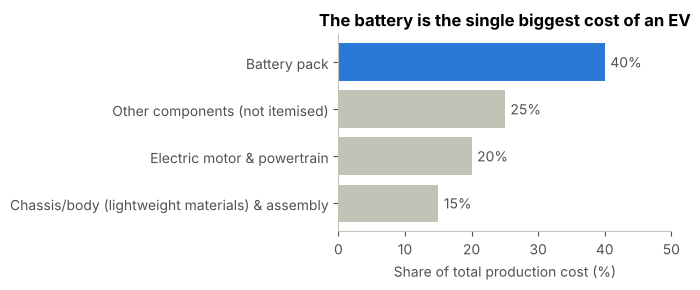

In [2]:
cost = pd.read_csv(DATA / "ev_production_cost_breakdown.csv")
cost = cost.sort_values("share_of_production_cost_pct")

fig, ax = plt.subplots(figsize=(7, 3))
colors = [ACCENT if c == "Battery pack" else NEUTRAL for c in cost["component"]]
bars = ax.barh(cost["component"], cost["share_of_production_cost_pct"], color=colors)
ax.bar_label(bars, fmt="%d%%", padding=4, color=INK)
ax.set_xlabel("Share of total production cost (%)")
ax.set_xlim(0, 50)
ax.set_title("The battery is the single biggest cost of an EV")
save(fig, "01_cost_breakdown.png")
plt.show()

**Reading the chart:** about 40% of the production cost is the battery. Whoever controls battery supply (cells, lithium, refining) controls most of the cost of the car. This is a **supply chain** question as much as a technology question.

## 2. Lithium: boom and bust

Lithium is often called the "new oil" or "white gold". Its price is very volatile.

Fall from the 2022 peak to 2023: 84.1%


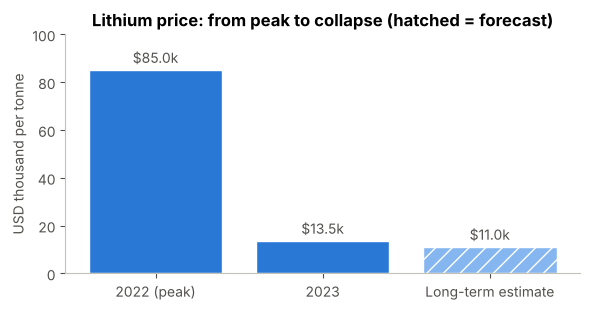

In [3]:
li = pd.read_csv(DATA / "lithium_price.csv")

fig, ax = plt.subplots(figsize=(6, 3.2))
colors = [ACCENT if t == "observed" else "#86b6ef" for t in li["type"]]
hatches = ["" if t == "observed" else "//" for t in li["type"]]
bars = ax.bar(li["period"], li["price_usd_per_tonne"] / 1000, color=colors, edgecolor="white")
for b, h in zip(bars, hatches):
    b.set_hatch(h)
ax.bar_label(bars, fmt="$%.1fk", padding=3, color=INK)
ax.set_ylabel("USD thousand per tonne")
ax.set_ylim(0, 100)
ax.set_title("Lithium price: from peak to collapse (hatched = forecast)")
save(fig, "02_lithium_price.png")
plt.show()

peak = li.loc[0, "price_usd_per_tonne"]
y2023 = li.loc[1, "price_usd_per_tonne"]
drop = (peak - y2023) / peak * 100
print(f"Fall from the 2022 peak to 2023: {drop:.1f}%")

**Reading the chart:** the price fell by about 84% in one year. For carmakers this is good news (cheaper batteries), but such swings make long-term planning and supplier contracts risky.

## 3. EV adoption in Europe

Share of new cars sold that are fully electric, by country (2024).

Norway's share is about 10 times Italy's.


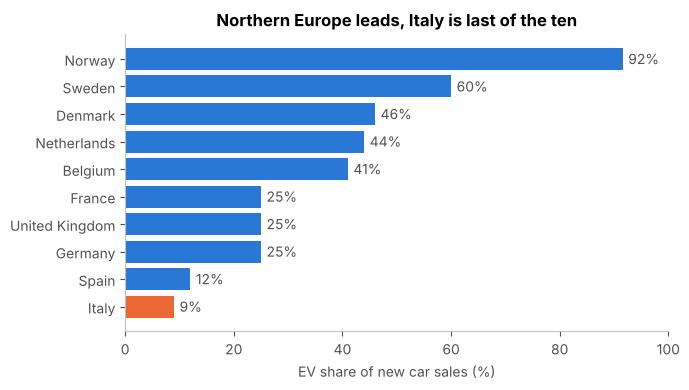

In [4]:
eu = pd.read_csv(DATA / "ev_market_share_europe_2024.csv")
eu = eu.sort_values("ev_share_of_new_car_sales_pct")

fig, ax = plt.subplots(figsize=(7, 4))
colors = [HIGHLIGHT if c == "Italy" else ACCENT for c in eu["country"]]
bars = ax.barh(eu["country"], eu["ev_share_of_new_car_sales_pct"], color=colors)
ax.bar_label(bars, fmt="%.0f%%", padding=4, color=INK)
ax.set_xlabel("EV share of new car sales (%)")
ax.set_xlim(0, 100)
ax.set_title("Northern Europe leads, Italy is last of the ten")
save(fig, "03_europe_market_share.png")
plt.show()

italy = eu.set_index("country").loc["Italy", "ev_share_of_new_car_sales_pct"]
norway = eu.set_index("country").loc["Norway", "ev_share_of_new_car_sales_pct"]
print(f"Norway's share is about {norway / italy:.0f} times Italy's.")

**Reading the chart:** the gap is huge, from 91.6% in Norway to 9% in Italy. The thesis links it to purchase incentives, energy prices and, above all, charging infrastructure.

## 4. Is charging infrastructure keeping up?

Italy: 297,917 EVs / 60,339 public points = 4.9 EVs per public charging point


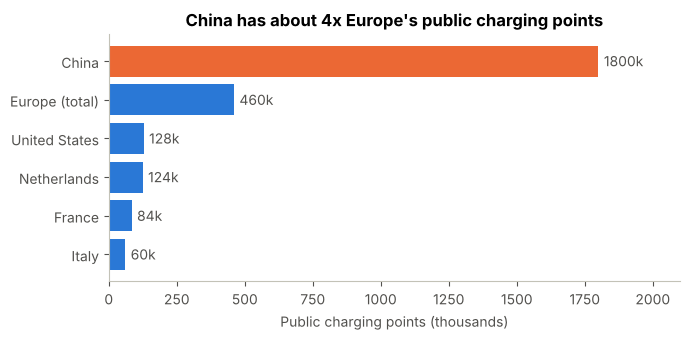

In [5]:
cp = pd.read_csv(DATA / "public_charging_points.csv")
cp = cp.sort_values("public_charging_points")

fig, ax = plt.subplots(figsize=(7, 3.5))
colors = [HIGHLIGHT if a == "China" else ACCENT for a in cp["area"]]
bars = ax.barh(cp["area"], cp["public_charging_points"] / 1000, color=colors)
ax.bar_label(bars, fmt="%.0fk", padding=4, color=INK)
ax.set_xlabel("Public charging points (thousands)")
ax.set_xlim(0, 2100)
ax.set_title("China has about 4x Europe's public charging points")
save(fig, "04_charging_points.png")
plt.show()

# A derived indicator: how many EVs share one public charging point in Italy?
kf = pd.read_csv(DATA / "key_figures.csv").set_index("metric")
italy_evs = kf.loc["Italy EVs on the road", "value"]
italy_points = cp.set_index("area").loc["Italy", "public_charging_points"]
print(f"Italy: {italy_evs:,.0f} EVs / {italy_points:,} public points "
      f"= {italy_evs / italy_points:.1f} EVs per public charging point")

**Reading the chart:** the reference periods differ a little (2022–2025), so read it as orders of magnitude, not exact comparisons. The derived ratio for Italy (about 5 EVs per public charger) shows that the Italian problem is less the number of chargers and more the cost of cars and of charging, which is what the thesis concludes.

## 5. How big could the charging market become?

Bloomberg estimates the global EV-charging-infrastructure market at **USD 44 billion in 2025**, growing at a **CAGR of 25.94%** until 2030.

**CAGR** (compound annual growth rate) means the market grows by the same *percentage* every year, so growth builds on growth:

$$\text{value}_{t} = \text{value}_{2025} \times (1 + g)^{\,t - 2025}$$

 year  market_usd_bn
 2025           44.0
 2026           55.4
 2027           69.8
 2028           87.9
 2029          110.7
 2030          139.4


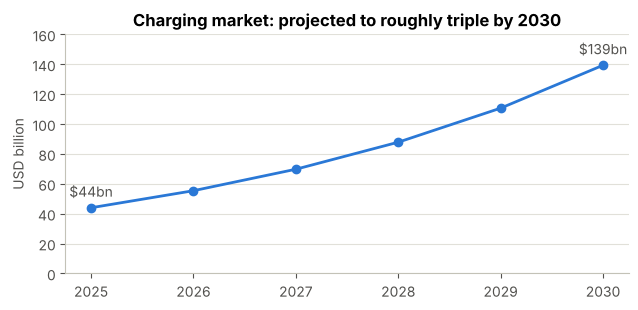

In [6]:
inp = pd.read_csv(DATA / "charging_market_forecast_inputs.csv").set_index("parameter")["value"]
start, g = inp["market_size_2025"], inp["cagr_2025_2030"] / 100

years = list(range(2025, 2031))
forecast = pd.DataFrame({
    "year": years,
    "market_usd_bn": [start * (1 + g) ** (y - 2025) for y in years],
})
print(forecast.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(forecast["year"], forecast["market_usd_bn"], color=ACCENT, linewidth=2, marker="o", markersize=6)
for x, y in zip(forecast["year"], forecast["market_usd_bn"]):
    if x in (2025, 2030):
        ax.annotate(f"${y:.0f}bn", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", color=INK)
ax.set_ylabel("USD billion")
ax.set_ylim(0, 160)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_title("Charging market: projected to roughly triple by 2030")
save(fig, "05_charging_market_forecast.png")
plt.show()

**Reading the chart:** at 25.94% a year the market multiplies by about 3.2 in five years. This is the investment idea of the thesis: the charging network is the "glue" that the whole EV transition depends on.

*Caution:* this is a simple projection of someone else's forecast, not an independent model.

## 6. The investment gap

Investment in clean technologies, 2018–2022 (BNEF data).

Ratio China / (Europe + US): 11.3x


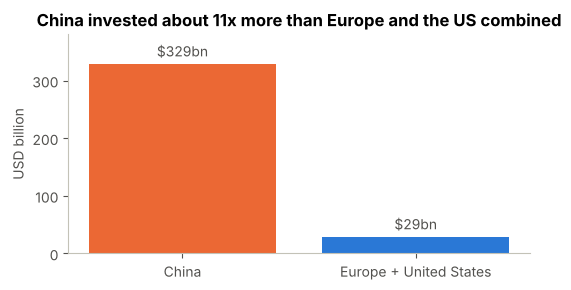

In [7]:
inv = pd.read_csv(DATA / "clean_tech_investment_2018_2022.csv")

fig, ax = plt.subplots(figsize=(5.5, 3))
colors = [HIGHLIGHT if r == "China" else ACCENT for r in inv["region"]]
bars = ax.bar(inv["region"], inv["investment_usd_billion"], color=colors)
ax.bar_label(bars, fmt="$%dbn", padding=3, color=INK)
ax.set_ylabel("USD billion")
ax.set_ylim(0, 380)
ax.set_title("China invested about 11x more than Europe and the US combined")
save(fig, "06_investment_gap.png")
plt.show()

ratio = inv.set_index("region").loc["China", "investment_usd_billion"] / \
        inv.set_index("region").loc["Europe + United States", "investment_usd_billion"]
print(f"Ratio China / (Europe + US): {ratio:.1f}x")

## Conclusions

- **Cost:** the battery (≈40% of the production cost) is the key to EV competitiveness.
- **Raw materials:** lithium prices are extremely volatile; China controls about 92% of battery production and much of the raw-material supply chain.
- **Adoption:** Northern Europe is far ahead; Italy lags behind (9% of sales, vs 91.6% in Norway).
- **Infrastructure and investment:** China leads in both, and the charging market is expected to roughly triple by 2030.

## Limitations

- The figures come from secondary sources (news sites, industry associations, market reports) collected in 2024–2025, as cited in the thesis.
- Reference periods differ between datasets, so cross-country comparisons are approximate.
- The 2030 market size is a mechanical projection of a published CAGR, not an independent forecast.